# 01 — Exploratory Data Analysis (Simple & Visual)
**Goal:** Understand our merged solar dataset using **simple code** and **clear charts**.

What we will look at:
1. Basic dataset info & missing values
2. Distributions (Histograms)
3. Quartiles & Outliers (Boxplots)
4. Correlation Heatmap
5. Weather vs Power (Scatter plots)
6. Time Patterns (Hourly & Daily charts)
7. Plant & Inverter Comparison


## 1. Load the Data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load our merged dataset
df = pd.read_csv("../data/processed/solar_panel_dataset.csv")
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()


Rows: 136476
Columns: 29


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,...,diffuse_radiation,direct_normal_irradiance,global_tilted_irradiance,precipitation,rain,is_day,HOUR,DAY_OF_YEAR,MONTH,TEMP_DIFF
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,25.184316,22.857507,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,136,5,-2.326809
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,25.184316,22.857507,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,136,5,-2.326809
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,25.184316,22.857507,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,136,5,-2.326809
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,25.184316,22.857507,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,136,5,-2.326809
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,25.184316,22.857507,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,136,5,-2.326809


## 2. Missing Values & Basic Stats (Min, Quartiles, Max)

In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Drop the 4 missing rows
df = df.dropna()
print("\nRows after dropping missing:", len(df))


Missing values:
AMBIENT_TEMPERATURE    4
MODULE_TEMPERATURE     4
IRRADIATION            4
TEMP_DIFF              4
dtype: int64

Rows after dropping missing: 136472


In [4]:
# Summary table: mean, min, 25%, 50% (median), 75%, max
key_cols = ["AC_POWER", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "relative_humidity_2m", "cloud_cover", "wind_speed_10m"]
df[key_cols].describe().round(2)


,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,relative_humidity_2m,cloud_cover,wind_speed_10m
count,136472.00,136472.00,136472.00,136472.00,136472.00,136472.00,136472.00
mean,274.79,0.23,26.76,31.92,71.38,80.58,13.84
std,380.18,0.31,3.90,11.80,19.25,27.45,5.46
min,0.00,0.00,20.40,18.14,20.00,0.00,1.40
25%,0.00,0.00,23.64,22.41,59.00,68.00,9.80
50%,3.49,0.03,25.91,26.41,74.00,96.00,13.40
75%,532.57,0.44,29.27,40.78,88.00,100.00,17.20
max,1410.95,1.22,39.18,66.64,99.00,100.00,28.90


## 3. Filter Daytime Only
At night, solar panels produce **0 power**. Let's create a `day` table with only daytime rows (`IRRADIATION > 0`) so our charts focus on real production.

In [5]:
day = df[df["IRRADIATION"] > 0]
print("Total rows:", len(df))
print("Daytime rows:", len(day))


Total rows: 136472
Daytime rows: 77098


## 4. Distributions (Histograms)
See the shape of our main variables during daytime.

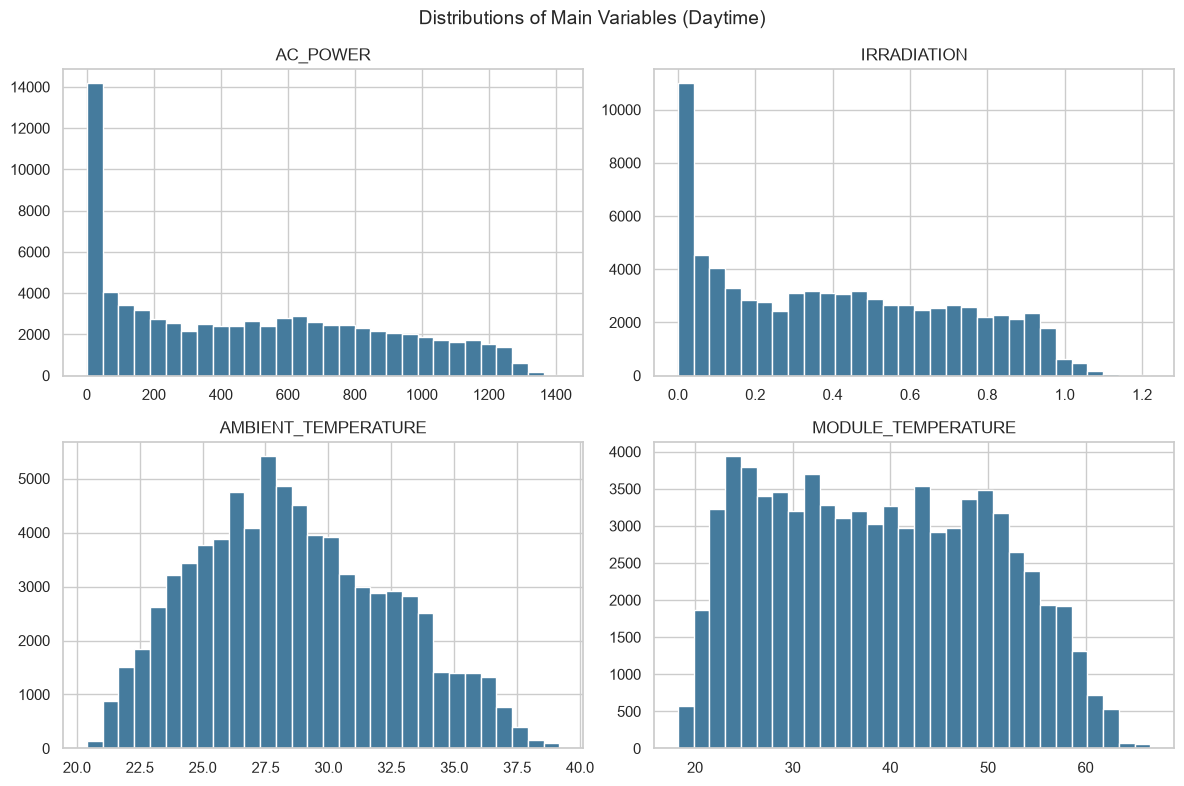

In [6]:
day[["AC_POWER", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]].hist(bins=30, figsize=(12, 8), color="#457b9d")
plt.suptitle("Distributions of Main Variables (Daytime)", fontsize=14)
plt.tight_layout()
plt.show()


## 5. Quartiles & Outliers (Boxplots)
Boxplots show the **25% quartile, median (50%), 75% quartile, and outliers** clearly.

C:\Users\hp\AppData\Local\Temp\ipykernel_19504\2890418498.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=day, x="PLANT_ID", y="AC_POWER", palette="Set2")


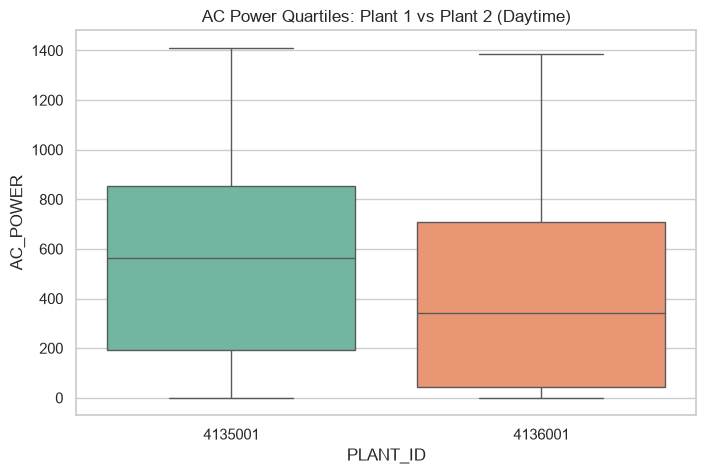

In [7]:
# Boxplot: AC_POWER for Plant 1 vs Plant 2
plt.figure(figsize=(8, 5))
sns.boxplot(data=day, x="PLANT_ID", y="AC_POWER", palette="Set2")
plt.title("AC Power Quartiles: Plant 1 vs Plant 2 (Daytime)")
plt.show()


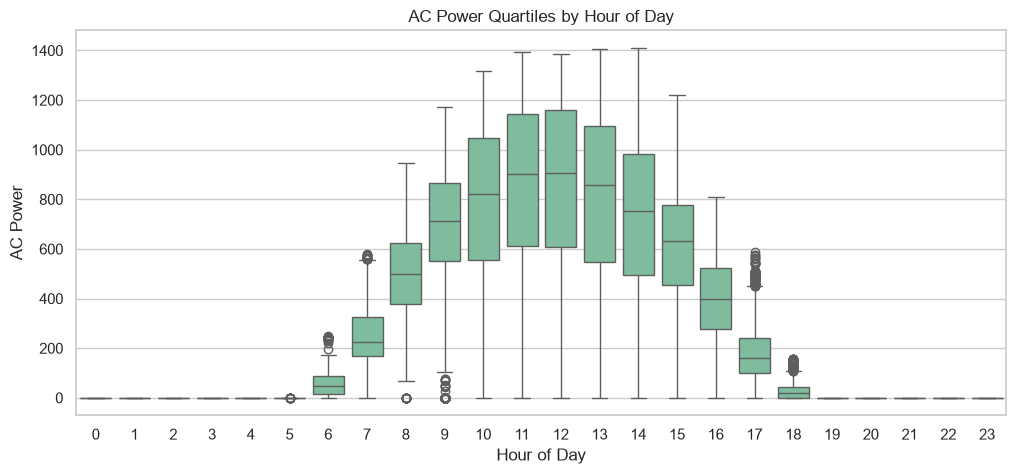

In [8]:
# Boxplot: AC_POWER by Hour of Day (shows spread & quartiles at every hour!)
plt.figure(figsize=(12, 5))
sns.boxplot(data=day, x="HOUR", y="AC_POWER", color="#74c69d")
plt.title("AC Power Quartiles by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("AC Power")
plt.show()


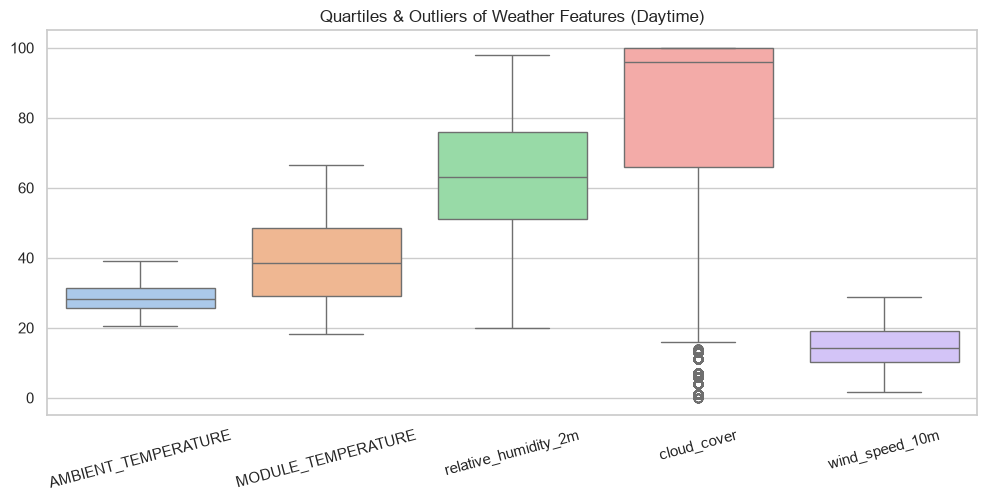

In [9]:
# Boxplots of main weather features
weather_box = ["AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "relative_humidity_2m", "cloud_cover", "wind_speed_10m"]
plt.figure(figsize=(12, 5))
sns.boxplot(data=day[weather_box], palette="pastel")
plt.title("Quartiles & Outliers of Weather Features (Daytime)")
plt.xticks(rotation=15)
plt.show()


## 6. Correlation Heatmap
Shows how strongly every feature moves together (`+1` = strong positive, `-1` = strong negative, `0` = no relation).

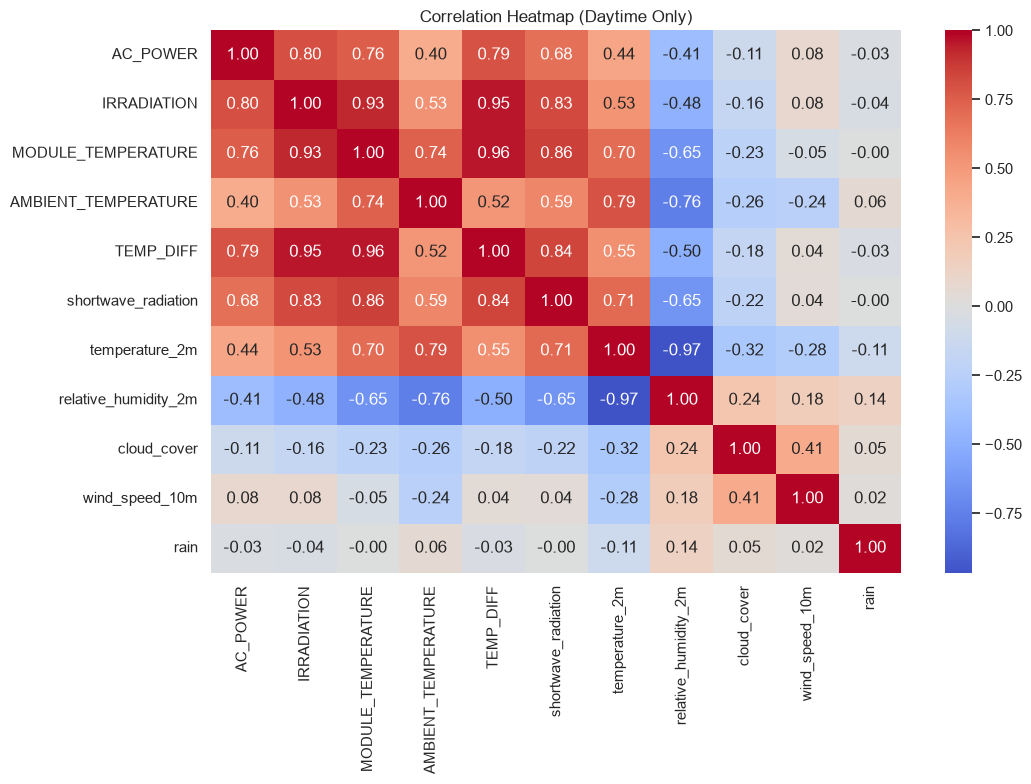

In [10]:
heat_cols = [
    "AC_POWER", "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF",
    "shortwave_radiation", "temperature_2m", "relative_humidity_2m", "cloud_cover", "wind_speed_10m", "rain"
]

plt.figure(figsize=(11, 8))
sns.heatmap(day[heat_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Daytime Only)")
plt.tight_layout()
plt.show()


## 7. Weather vs AC Power (Scatter Plots)
Let's see the direct relationship between sunlight/temperature and power output.

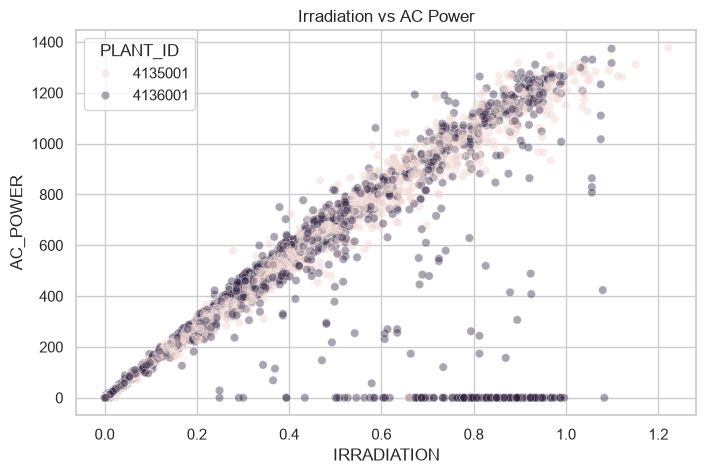

In [12]:
sample = day.sample(3000)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="IRRADIATION", y="AC_POWER", hue="PLANT_ID", alpha=0.4)
plt.title("Irradiation vs AC Power")
plt.show()


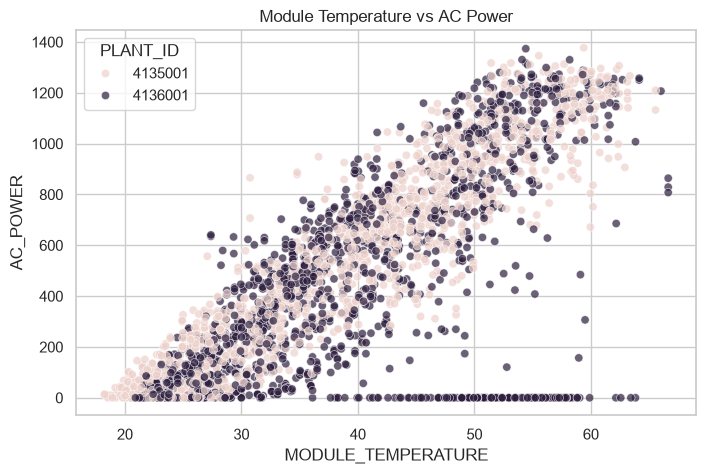

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="MODULE_TEMPERATURE", y="AC_POWER", hue="PLANT_ID", alpha=0.7)
plt.title("Module Temperature vs AC Power")
plt.show()


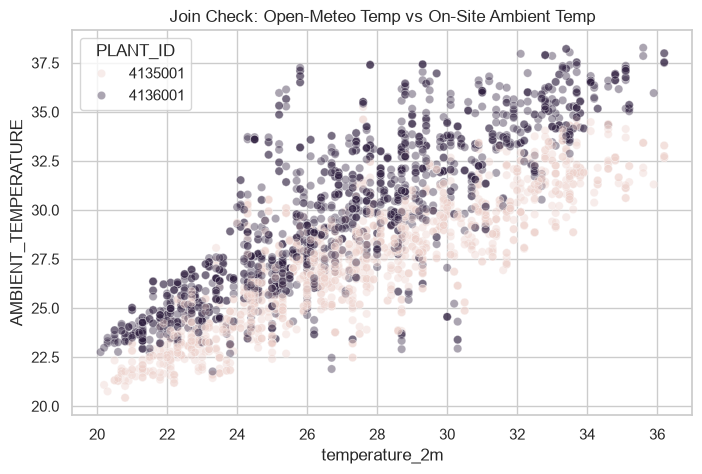

In [18]:
# Join sanity check: On-site temperature vs Open-Meteo temperature
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="temperature_2m", y="AMBIENT_TEMPERATURE", hue="PLANT_ID", alpha=0.4)
plt.title("Join Check: Open-Meteo Temp vs On-Site Ambient Temp")
plt.show()


## 8. Time Patterns (Hourly & Daily)

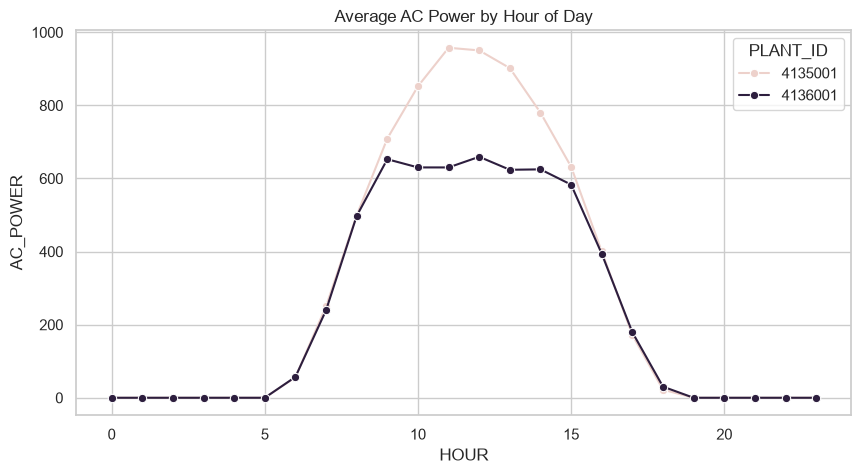

In [19]:
# Average AC Power by Hour of Day
hourly = df.groupby(["PLANT_ID", "HOUR"])["AC_POWER"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly, x="HOUR", y="AC_POWER", hue="PLANT_ID", marker="o")
plt.title("Average AC Power by Hour of Day")
plt.show()


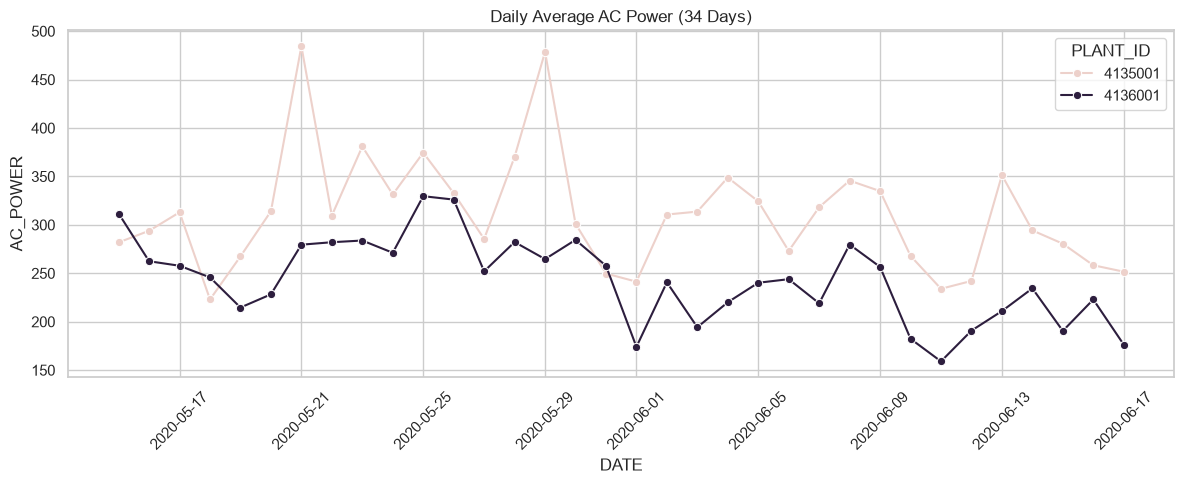

In [20]:
# Average AC Power per Day over the 34 days
df["DATE"] = df["DATE_TIME"].dt.date
daily = df.groupby(["PLANT_ID", "DATE"])["AC_POWER"].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=daily, x="DATE", y="AC_POWER", hue="PLANT_ID", marker="o")
plt.title("Daily Average AC Power (34 Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 9. Inverter Comparison (Loss Analysis Preview)
Are all inverters in the same plant producing the same power?

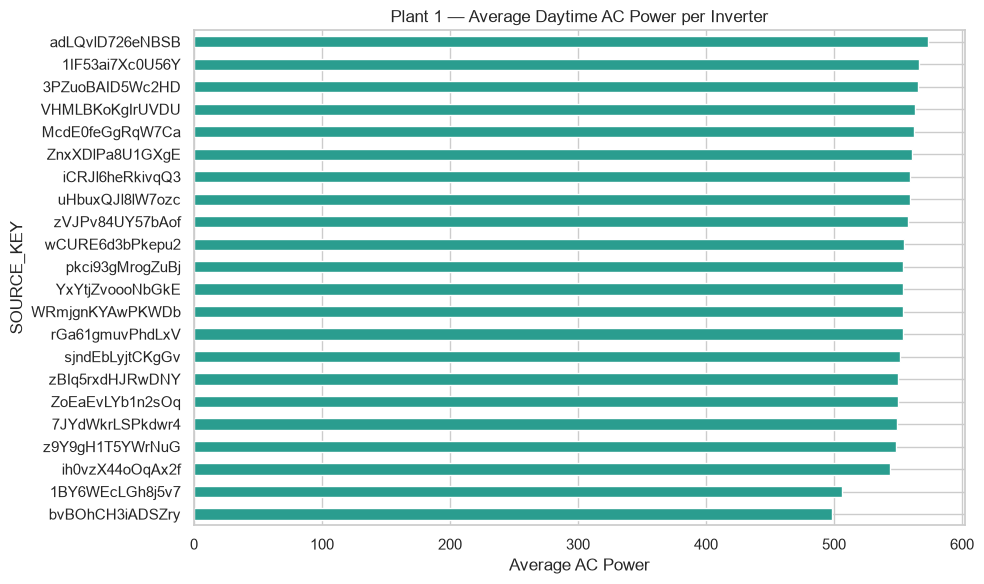

In [15]:
# Plant 1 inverters
p1 = day[day["PLANT_ID"] == 4135001]
p1_inv = p1.groupby("SOURCE_KEY")["AC_POWER"].mean().sort_values()

plt.figure(figsize=(10, 6))
p1_inv.plot(kind="barh", color="#2a9d8f")
plt.title("Plant 1 — Average Daytime AC Power per Inverter")
plt.xlabel("Average AC Power")
plt.tight_layout()
plt.show()


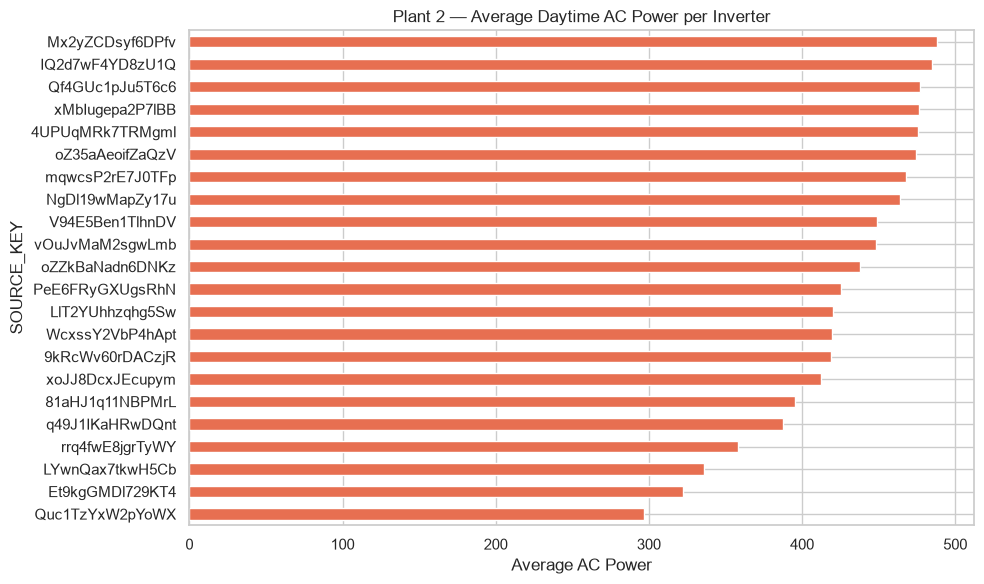

In [16]:
# Plant 2 inverters
p2 = day[day["PLANT_ID"] == 4136001]
p2_inv = p2.groupby("SOURCE_KEY")["AC_POWER"].mean().sort_values()

plt.figure(figsize=(10, 6))
p2_inv.plot(kind="barh", color="#e76f51")
plt.title("Plant 2 — Average Daytime AC Power per Inverter")
plt.xlabel("Average AC Power")
plt.tight_layout()
plt.show()
